# Retrieval Results Visualization

This notebook combines precomputed retrieval outputs from the primary, ASHR, and z-score runs across 6 datasets and 20 directed dataset pairs. Shared `logFC` scores are checked before merging; comparisons use `cosine`, `pearson`, and `mrrmse`.

The coverage audit identifies missing pairs and pairs with few matched queries.


In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
except ImportError as exc:
    raise ImportError(
        "This notebook requires seaborn. Install with: uv add seaborn or pip install seaborn"
    ) from exc

from IPython.display import display

sns.set_theme(
    style="whitegrid",
    context="talk",
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "#F8FAFC",
        "axes.edgecolor": "#D1D5DB",
        "grid.color": "#E5E7EB",
        "axes.titleweight": "bold",
    },
)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

In [2]:
# Primary CIGS-inclusive run.
OUTPUT_PREFIX = "cross_dataset_retrieval_parallel_cigs"
RESULTS_SUBDIR = "representation_sweep/cross_dataset_retrieval_parallel_cigs"
# Notebook exports go here, kept apart from the input run directories.
OUTPUT_SUBDIR = "representation_sweep/visualize_retrieval_results"

# Keep native sign(logFC); the separate direction run uses different datasets.
DIRECTION_OUTPUT_PREFIX = "cross_dataset_retrieval_logfc_vs_direction"
DIRECTION_RESULTS_SUBDIR = "cross_dataset_retrieval_logfc_vs_direction"
MERGE_SIGN_LOGFC = False
DIRECTION_REPRESENTATION = "sign(logFC)"

# ASHR results from the supplemental run.
MERGE_ASHR = True
ASHR_OUTPUT_PREFIX = "cross_dataset_retrieval_parallel_ashr"
ASHR_RESULTS_SUBDIR = "representation_sweep/cross_dataset_retrieval_parallel_ashr"
# Use the cell-line scope only.
ASHR_REPRESENTATION = "ashr_posterior_mean(logFC)_cell_line"
# Keep metrics shared with the primary run.
ASHR_METRICS = ("cosine", "mrrmse", "pearson")
# Include detail scores in case this representation wins.
ASHR_MERGE_DETAIL = True

# Take both z-score scopes from the supplemental run, replacing the primary copy.
MERGE_ZSCORE = True
ZSCORE_OUTPUT_PREFIX = "cross_dataset_retrieval_parallel_cigs_zscore"
ZSCORE_RESULTS_SUBDIR = "representation_sweep/cross_dataset_retrieval_parallel_cigs_zscore"
ZSCORE_REPRESENTATIONS = (
    "per_gene_population_zscore(logFC)",
    "per_gene_population_zscore_dataset",
)
# Include detail scores in case this representation wins.
ZSCORE_MERGE_DETAIL = True

# None keeps all representations.
REPRESENTATIONS_KEEP = None

# Sampling applies only to the detail plot.
DETAIL_SAMPLE_PER_GROUP = 4000
RANDOM_STATE = 7

candidate_roots = [Path("."), Path("..")]


def resolve_results_dir(subdir: str) -> Path:
    for root in candidate_roots:
        candidate = (root / "results" / subdir).resolve()
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find results directory. Expected ./results/{subdir} or ../results/{subdir}."
    )


def read_csv_required(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")
    return pd.read_csv(path)


def read_csv_optional(path: Path) -> pd.DataFrame:
    return pd.read_csv(path) if path.exists() else pd.DataFrame()


def merge_representation_rows(
    primary: pd.DataFrame,
    extra: pd.DataFrame,
    *,
    representation: str,
) -> pd.DataFrame:
    """Keep all primary rows except `representation`, then append that representation from extra."""
    if extra.empty or "representation" not in extra.columns:
        return primary
    extra_rep = extra.loc[extra["representation"].astype(str) == representation].copy()
    if extra_rep.empty:
        return primary
    if primary.empty:
        return extra_rep.reset_index(drop=True)
    primary_out = primary.loc[primary["representation"].astype(str) != representation].copy()
    return pd.concat([primary_out, extra_rep], ignore_index=True)


def restrict_to_metrics(df: pd.DataFrame, metrics: tuple[str, ...]) -> pd.DataFrame:
    if df.empty or "metric" not in df.columns:
        return df
    return df.loc[df["metric"].astype(str).isin(metrics)].copy()


def check_shared_representation(
    primary: pd.DataFrame,
    extra: pd.DataFrame,
    *,
    representation: str = "logFC",
    value_col: str = "retrieval_score_mean",
) -> None:
    """Assert two runs agree on a representation both scored, before merging them.

    Anything non-zero here means the runs are not interchangeable -- different gene
    masking, dataset set, or code -- and their rows must not be pooled into one table.
    """
    keys = ["query_dataset", "db_dataset", "metric"]
    if extra.empty or not {*keys, value_col} <= set(extra.columns):
        return
    left = primary.loc[primary["representation"].astype(str) == representation]
    right = extra.loc[extra["representation"].astype(str) == representation]
    if left.empty or right.empty:
        print(f"NOTE: {representation} missing from one run; cannot cross-check the merge")
        return
    both = left.merge(right, on=keys, suffixes=("_primary", "_extra"))
    delta = (both[f"{value_col}_primary"] - both[f"{value_col}_extra"]).abs()
    worst = float(delta.max()) if len(both) else float("nan")
    if len(both) and worst > 1e-9:
        raise ValueError(
            f"{representation} disagrees between runs on {int((delta > 1e-9).sum())} of "
            f"{len(both)} shared rows (max |diff| = {worst:.3g}); refusing to merge."
        )
    print(
        f"Cross-check: {representation} identical across both runs "
        f"on all {len(both)} shared (pair, metric) rows."
    )


results_dir = resolve_results_dir(RESULTS_SUBDIR)
output_dir = results_dir.parents[len(Path(RESULTS_SUBDIR).parts) - 1] / OUTPUT_SUBDIR
output_dir.mkdir(parents=True, exist_ok=True)
paths = {
    "summary_overall": results_dir / f"{OUTPUT_PREFIX}_summary_overall.csv",
    "summary_by_cell": results_dir / f"{OUTPUT_PREFIX}_summary_by_cell_type.csv",
    "detail": results_dir / f"{OUTPUT_PREFIX}_detail.csv",
    "tasks": results_dir / f"{OUTPUT_PREFIX}_tasks.csv",
    "truth_summary": results_dir / f"{OUTPUT_PREFIX}_truth_summary.csv",
    "truth_matches": results_dir / f"{OUTPUT_PREFIX}_truth_matches.csv",
}

summary_overall_df = read_csv_required(paths["summary_overall"])
summary_by_cell_df = read_csv_required(paths["summary_by_cell"])
detail_df = read_csv_required(paths["detail"])
tasks_df = read_csv_optional(paths["tasks"])
truth_summary_df = read_csv_optional(paths["truth_summary"])
truth_matches_df = read_csv_optional(paths["truth_matches"])

direction_dir = None
if MERGE_SIGN_LOGFC:
    try:
        direction_dir = resolve_results_dir(DIRECTION_RESULTS_SUBDIR)
    except FileNotFoundError as exc:
        print(f"WARNING: direction results not found; skipping sign(logFC) merge ({exc})")
        direction_dir = None

if direction_dir is not None:
    dir_paths = {
        "summary_overall": direction_dir / f"{DIRECTION_OUTPUT_PREFIX}_summary_overall.csv",
        "summary_by_cell": direction_dir / f"{DIRECTION_OUTPUT_PREFIX}_summary_by_cell_type.csv",
        "detail": direction_dir / f"{DIRECTION_OUTPUT_PREFIX}_detail.csv",
        "tasks": direction_dir / f"{DIRECTION_OUTPUT_PREFIX}_tasks.csv",
    }
    dir_overall = read_csv_optional(dir_paths["summary_overall"])
    dir_by_cell = read_csv_optional(dir_paths["summary_by_cell"])
    dir_detail = read_csv_optional(dir_paths["detail"])
    dir_tasks = read_csv_optional(dir_paths["tasks"])

    before = len(summary_overall_df)
    summary_overall_df = merge_representation_rows(
        summary_overall_df, dir_overall, representation=DIRECTION_REPRESENTATION
    )
    print(f"Merged {DIRECTION_REPRESENTATION} into summary_overall: {before:,} -> {len(summary_overall_df):,}")

    before = len(summary_by_cell_df)
    summary_by_cell_df = merge_representation_rows(
        summary_by_cell_df, dir_by_cell, representation=DIRECTION_REPRESENTATION
    )
    print(f"Merged {DIRECTION_REPRESENTATION} into summary_by_cell: {before:,} -> {len(summary_by_cell_df):,}")

    if not dir_detail.empty:
        before = len(detail_df)
        detail_df = merge_representation_rows(
            detail_df, dir_detail, representation=DIRECTION_REPRESENTATION
        )
        print(f"Merged {DIRECTION_REPRESENTATION} into detail: {before:,} -> {len(detail_df):,}")

    if not dir_tasks.empty:
        before = len(tasks_df)
        tasks_df = merge_representation_rows(
            tasks_df, dir_tasks, representation=DIRECTION_REPRESENTATION
        )
        print(f"Merged {DIRECTION_REPRESENTATION} into tasks: {before:,} -> {len(tasks_df):,}")

ashr_dir = None
if MERGE_ASHR:
    try:
        ashr_dir = resolve_results_dir(ASHR_RESULTS_SUBDIR)
    except FileNotFoundError as exc:
        print(f"WARNING: ashr results not found; skipping ashr merge ({exc})")
        ashr_dir = None

if ashr_dir is not None:
    ashr_paths = {
        "summary_overall": ashr_dir / f"{ASHR_OUTPUT_PREFIX}_summary_overall.csv",
        "summary_by_cell": ashr_dir / f"{ASHR_OUTPUT_PREFIX}_summary_by_cell_type.csv",
        "detail": ashr_dir / f"{ASHR_OUTPUT_PREFIX}_detail.csv",
        "tasks": ashr_dir / f"{ASHR_OUTPUT_PREFIX}_tasks.csv",
    }
    ashr_overall = restrict_to_metrics(read_csv_optional(ashr_paths["summary_overall"]), ASHR_METRICS)
    ashr_by_cell = restrict_to_metrics(read_csv_optional(ashr_paths["summary_by_cell"]), ASHR_METRICS)
    ashr_tasks = restrict_to_metrics(read_csv_optional(ashr_paths["tasks"]), ASHR_METRICS)

    # Check shared logFC scores before merging.
    check_shared_representation(summary_overall_df, ashr_overall, representation="logFC")

    before = len(summary_overall_df)
    summary_overall_df = merge_representation_rows(
        summary_overall_df, ashr_overall, representation=ASHR_REPRESENTATION
    )
    print(f"Merged {ASHR_REPRESENTATION} into summary_overall: {before:,} -> {len(summary_overall_df):,}")

    before = len(summary_by_cell_df)
    summary_by_cell_df = merge_representation_rows(
        summary_by_cell_df, ashr_by_cell, representation=ASHR_REPRESENTATION
    )
    print(f"Merged {ASHR_REPRESENTATION} into summary_by_cell: {before:,} -> {len(summary_by_cell_df):,}")

    if not ashr_tasks.empty:
        before = len(tasks_df)
        tasks_df = merge_representation_rows(
            tasks_df, ashr_tasks, representation=ASHR_REPRESENTATION
        )
        print(f"Merged {ASHR_REPRESENTATION} into tasks: {before:,} -> {len(tasks_df):,}")

    if ASHR_MERGE_DETAIL:
        ashr_detail = restrict_to_metrics(read_csv_optional(ashr_paths["detail"]), ASHR_METRICS)
        if not ashr_detail.empty:
            before = len(detail_df)
            detail_df = merge_representation_rows(
                detail_df, ashr_detail, representation=ASHR_REPRESENTATION
            )
            print(f"Merged {ASHR_REPRESENTATION} into detail: {before:,} -> {len(detail_df):,}")
        del ashr_detail

zscore_dir = None
if MERGE_ZSCORE:
    try:
        zscore_dir = resolve_results_dir(ZSCORE_RESULTS_SUBDIR)
    except FileNotFoundError as exc:
        print(f"WARNING: z-score results not found; skipping z-score merge ({exc})")
        zscore_dir = None

if zscore_dir is not None:
    zscore_paths = {
        "summary_overall": zscore_dir / f"{ZSCORE_OUTPUT_PREFIX}_summary_overall.csv",
        "summary_by_cell": zscore_dir / f"{ZSCORE_OUTPUT_PREFIX}_summary_by_cell_type.csv",
        "detail": zscore_dir / f"{ZSCORE_OUTPUT_PREFIX}_detail.csv",
        "tasks": zscore_dir / f"{ZSCORE_OUTPUT_PREFIX}_tasks.csv",
    }
    zscore_overall = read_csv_optional(zscore_paths["summary_overall"])
    zscore_by_cell = read_csv_optional(zscore_paths["summary_by_cell"])
    zscore_tasks = read_csv_optional(zscore_paths["tasks"])

    check_shared_representation(summary_overall_df, zscore_overall, representation="logFC")

    for zscore_representation in ZSCORE_REPRESENTATIONS:
        before = len(summary_overall_df)
        summary_overall_df = merge_representation_rows(
            summary_overall_df, zscore_overall, representation=zscore_representation
        )
        print(
            f"Merged {zscore_representation} into summary_overall: "
            f"{before:,} -> {len(summary_overall_df):,}"
        )

        before = len(summary_by_cell_df)
        summary_by_cell_df = merge_representation_rows(
            summary_by_cell_df, zscore_by_cell, representation=zscore_representation
        )
        print(
            f"Merged {zscore_representation} into summary_by_cell: "
            f"{before:,} -> {len(summary_by_cell_df):,}"
        )

        if not zscore_tasks.empty:
            before = len(tasks_df)
            tasks_df = merge_representation_rows(
                tasks_df, zscore_tasks, representation=zscore_representation
            )
            print(
                f"Merged {zscore_representation} into tasks: "
                f"{before:,} -> {len(tasks_df):,}"
            )

    if ZSCORE_MERGE_DETAIL:
        zscore_detail = read_csv_optional(zscore_paths["detail"])
        if not zscore_detail.empty:
            for zscore_representation in ZSCORE_REPRESENTATIONS:
                before = len(detail_df)
                detail_df = merge_representation_rows(
                    detail_df, zscore_detail, representation=zscore_representation
                )
                print(
                    f"Merged {zscore_representation} into detail: "
                    f"{before:,} -> {len(detail_df):,}"
                )
        del zscore_detail

if REPRESENTATIONS_KEEP is not None:
    keep = set(REPRESENTATIONS_KEEP)

    def _filter(df: pd.DataFrame) -> pd.DataFrame:
        if df.empty or "representation" not in df.columns:
            return df
        return df.loc[df["representation"].isin(keep)].copy()

    summary_overall_df = _filter(summary_overall_df)
    summary_by_cell_df = _filter(summary_by_cell_df)
    detail_df = _filter(detail_df)
    tasks_df = _filter(tasks_df)
    print(f"Filtered tables to representations: {sorted(keep)}")

print(f"Primary results directory: ./results/{RESULTS_SUBDIR}")
if direction_dir is not None:
    print(f"Direction results directory: ./results/{DIRECTION_RESULTS_SUBDIR}")
if ashr_dir is not None:
    print(f"ashr results directory: ./results/{ASHR_RESULTS_SUBDIR}")
if zscore_dir is not None:
    print(f"z-score results directory: ./results/{ZSCORE_RESULTS_SUBDIR}")
for key, p in paths.items():
    exists = p.exists()
    size = f"{p.stat().st_size / 1e6:.1f} MB" if exists else "missing"
    print(f"- {key:14s} | exists={str(exists):5s} | {p.name} | {size}")
print(
    "Representations in summary_overall:",
    sorted(summary_overall_df["representation"].dropna().astype(str).unique().tolist()),
)


Cross-check: logFC identical across both runs on all 60 shared (pair, metric) rows.
Merged ashr_posterior_mean(logFC)_cell_line into summary_overall: 540 -> 600
Merged ashr_posterior_mean(logFC)_cell_line into summary_by_cell: 1,944 -> 2,160
Merged ashr_posterior_mean(logFC)_cell_line into tasks: 648 -> 720
Merged ashr_posterior_mean(logFC)_cell_line into detail: 1,803,711 -> 2,013,045
Cross-check: logFC identical across both runs on all 60 shared (pair, metric) rows.
Merged per_gene_population_zscore(logFC) into summary_overall: 600 -> 600
Merged per_gene_population_zscore(logFC) into summary_by_cell: 2,160 -> 2,160
Merged per_gene_population_zscore(logFC) into tasks: 720 -> 720
Merged per_gene_population_zscore_dataset into summary_overall: 600 -> 660
Merged per_gene_population_zscore_dataset into summary_by_cell: 2,160 -> 2,376
Merged per_gene_population_zscore_dataset into tasks: 720 -> 792
Merged per_gene_population_zscore(logFC) into detail: 2,013,045 -> 2,013,045
Merged per_gene

In [3]:
for df in [summary_overall_df, summary_by_cell_df, detail_df, tasks_df, truth_summary_df]:
    if not df.empty and {"query_dataset", "db_dataset"}.issubset(df.columns):
        df["pair"] = df["query_dataset"].astype(str) + " -> " + df["db_dataset"].astype(str)

pair_order = sorted(summary_overall_df["pair"].dropna().unique().tolist())
metric_order = sorted(summary_overall_df["metric"].dropna().unique().tolist())
representation_order = (
    summary_overall_df.groupby("representation", as_index=False)["retrieval_score_mean"]
    .mean()
    .sort_values("retrieval_score_mean", ascending=False)["representation"]
    .tolist()
)

overview = pd.DataFrame(
    [
        {"table": "summary_overall", "rows": len(summary_overall_df)},
        {"table": "summary_by_cell", "rows": len(summary_by_cell_df)},
        {"table": "detail", "rows": len(detail_df)},
        {"table": "tasks", "rows": len(tasks_df)},
        {"table": "truth_summary", "rows": len(truth_summary_df)},
        {"table": "truth_matches", "rows": len(truth_matches_df)},
    ]
)
display(overview)

display(
    summary_overall_df.sort_values("retrieval_score_mean", ascending=False)
    .head(12)
    .reset_index(drop=True)
)
            


,table,rows
0,summary_overall,660
1,summary_by_cell,2376
2,detail,2222379
3,tasks,792
4,truth_summary,72
5,truth_matches,69778


,query_dataset,db_dataset,representation,metric,n_queries,n_candidates_mean,n_candidates_median,rank_mean,rank_median,rank_over_n_mean,rank_normalized_mean,retrieval_score_mean,retrieval_score_median,pair
0,l1000_phase1,cigs_tcm,logFC,mrrmse,8,4312.0,4312.0,195.625000,212.0,0.045368,0.045146,0.954854,0.951055,l1000_phase1 -> cigs_tcm
1,cigs_mce,l1000_phase2,logFC,cosine,72,1638.0,1638.0,220.250000,21.5,0.134463,0.133934,0.866066,0.987477,cigs_mce -> l1000_phase2
2,cigs_mce,l1000_phase2,logFC,pearson,72,1638.0,1638.0,221.736111,20.5,0.135370,0.134842,0.865158,0.988088,cigs_mce -> l1000_phase2
3,cigs_mce,l1000_phase2,t,cosine,72,1638.0,1638.0,223.138889,14.0,0.136226,0.135699,0.864301,0.992059,cigs_mce -> l1000_phase2
4,cigs_mce,l1000_phase2,t,pearson,72,1638.0,1638.0,223.930556,13.0,0.136710,0.136182,0.863818,0.992670,cigs_mce -> l1000_phase2
5,cigs_mce,l1000_phase2,ashr_posterior_mean(logFC)_cell_line,pearson,72,1638.0,1638.0,229.680556,30.0,0.140220,0.139695,0.860305,0.982285,cigs_mce -> l1000_phase2
6,cigs_mce,l1000_phase2,ashr_posterior_mean(logFC)_cell_line,cosine,72,1638.0,1638.0,231.694444,27.0,0.141450,0.140925,0.859075,0.984117,cigs_mce -> l1000_phase2
7,l1000_phase1,cigs_tcm,per_gene_population_zscore_dataset,mrrmse,8,4312.0,4312.0,654.750000,632.5,0.151844,0.151647,0.848353,0.853514,l1000_phase1 -> cigs_tcm
8,cigs_mce,l1000_phase2,signed_-log10(p)*sign(logFC),cosine,72,1638.0,1638.0,260.361111,100.0,0.158951,0.158437,0.841563,0.939524,cigs_mce -> l1000_phase2
9,cigs_mce,l1000_phase2,signed_-log10(p)*sign(logFC),pearson,72,1638.0,1638.0,260.750000,98.0,0.159188,0.158674,0.841326,0.940745,cigs_mce -> l1000_phase2


In [4]:
# Pairs without usable matches are omitted upstream.
THIN_PAIR_TRUTH_QUERIES = 30

if truth_summary_df.empty:
    print("No truth_summary table; skipping coverage audit.")
else:
    all_datasets = sorted(
        set(truth_summary_df["query_dataset"].astype(str))
        | set(truth_summary_df["db_dataset"].astype(str))
    )
    scored_pairs = set(
        zip(
            truth_summary_df["query_dataset"].astype(str),
            truth_summary_df["db_dataset"].astype(str),
        )
    )
    missing_pairs = [
        (q, d)
        for q in all_datasets
        for d in all_datasets
        if q != d and (q, d) not in scored_pairs
    ]

    n_possible = len(all_datasets) * (len(all_datasets) - 1)
    print(f"Datasets: {all_datasets}")
    print(
        f"Ordered pairs: {len(scored_pairs)} scored / {n_possible} possible "
        f"({len(missing_pairs)} with zero matches)"
    )

    for column in ("n_shared_pubchem_cids", "n_truth_queries"):
        if column in truth_summary_df.columns:
            n_zero = int((truth_summary_df[column].fillna(0) == 0).sum())
            print(f"  rows with {column} == 0: {n_zero}")

    if missing_pairs:
        unordered = sorted({tuple(sorted(pair)) for pair in missing_pairs})
        print("\nZero-match pairs (absent from every table):")
        for left, right in unordered:
            directions = [
                f"{q}->{d}" for q, d in missing_pairs if tuple(sorted((q, d))) == (left, right)
            ]
            scope = "both directions" if len(directions) == 2 else " and ".join(directions)
            print(f"  {left} <-> {right}  ({scope})")

    pair_coverage = (
        truth_summary_df.groupby(["query_dataset", "db_dataset"], as_index=False)
        .agg(
            n_cell_types=("query_cell_type", "nunique"),
            n_shared_pubchem_cids=("n_shared_pubchem_cids", "sum"),
            n_truth_queries=("n_truth_queries", "sum"),
        )
        .sort_values("n_truth_queries")
        .reset_index(drop=True)
    )
    pair_coverage["thin"] = pair_coverage["n_truth_queries"] < THIN_PAIR_TRUTH_QUERIES

    thin_pairs = pair_coverage.loc[pair_coverage["thin"]]
    if not thin_pairs.empty:
        print(
            f"\nThin pairs (< {THIN_PAIR_TRUTH_QUERIES} truth queries) — scores here are "
            "essentially noise:"
        )
        for row in thin_pairs.itertuples():
            print(
                f"  {row.query_dataset} -> {row.db_dataset}: "
                f"{row.n_truth_queries} truth queries, "
                f"{row.n_shared_pubchem_cids} shared compounds, "
                f"{row.n_cell_types} cell type(s)"
            )

    display(pair_coverage)

Datasets: ['cigs_mce', 'cigs_tcm', 'l1000_phase1', 'l1000_phase2', 'sciplex', 'tahoe']
Ordered pairs: 20 scored / 30 possible (10 with zero matches)
  rows with n_shared_pubchem_cids == 0: 0
  rows with n_truth_queries == 0: 0

Zero-match pairs (absent from every table):
  cigs_mce <-> sciplex  (both directions)
  cigs_mce <-> tahoe  (both directions)
  cigs_tcm <-> l1000_phase2  (both directions)
  cigs_tcm <-> sciplex  (both directions)
  cigs_tcm <-> tahoe  (both directions)

Thin pairs (< 30 truth queries) — scores here are essentially noise:
  cigs_tcm -> l1000_phase1: 2 truth queries, 1 shared compounds, 1 cell type(s)
  l1000_phase1 -> cigs_tcm: 8 truth queries, 1 shared compounds, 1 cell type(s)


,query_dataset,db_dataset,n_cell_types,n_shared_pubchem_cids,n_truth_queries,thin
0,cigs_tcm,l1000_phase1,1,1,2,True
1,l1000_phase1,cigs_tcm,1,1,8,True
2,cigs_mce,l1000_phase2,1,68,72,False
3,tahoe,sciplex,1,23,72,False
4,sciplex,tahoe,1,23,119,False
5,cigs_mce,l1000_phase1,2,127,133,False
6,tahoe,l1000_phase2,3,143,438,False
7,sciplex,l1000_phase2,2,128,561,False
8,l1000_phase1,tahoe,6,257,633,False
9,tahoe,l1000_phase1,6,257,774,False


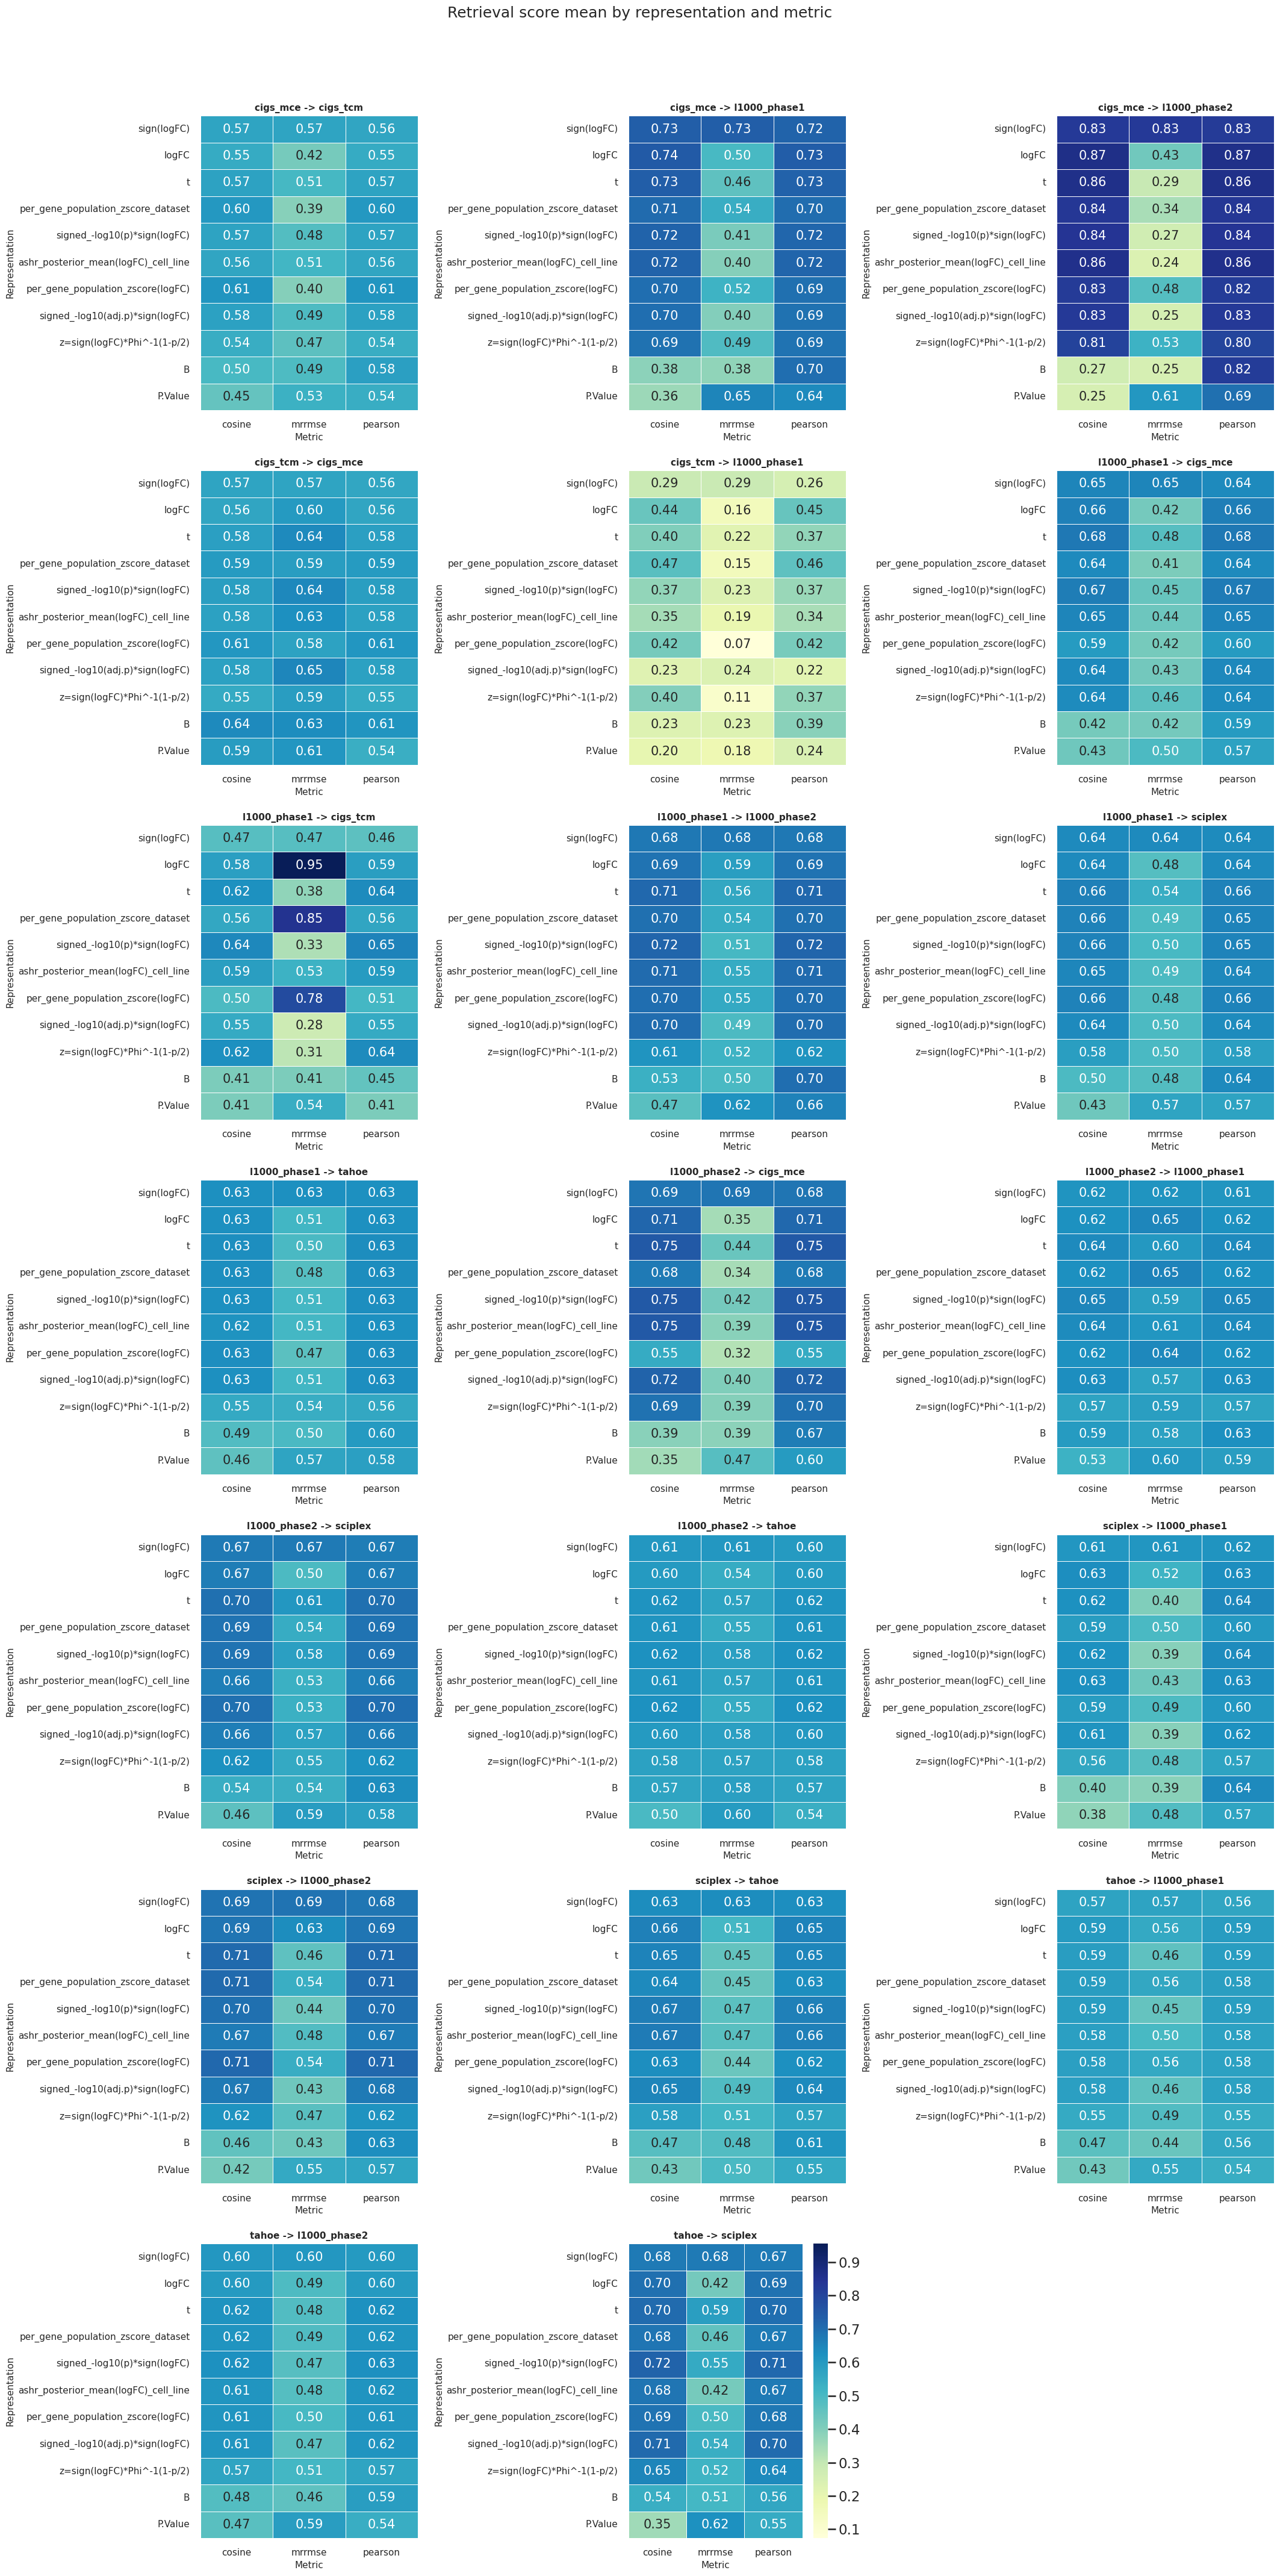

In [5]:
# Overall score heatmaps: one panel per query->db pair.
n_pairs = len(pair_order)
if n_pairs == 0:
    raise ValueError("No dataset pairs found in summary_overall_df.")

ncols = min(3, n_pairs)
nrows = math.ceil(n_pairs / ncols)

vmin = float(summary_overall_df["retrieval_score_mean"].min())
vmax = float(summary_overall_df["retrieval_score_mean"].max())

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7.2 * ncols, 6.0 * nrows))
axes = np.atleast_1d(axes).ravel()

for idx, pair in enumerate(pair_order):
    ax = axes[idx]
    sub = summary_overall_df.loc[summary_overall_df["pair"] == pair]
    pivot = sub.pivot(index="representation", columns="metric", values="retrieval_score_mean")
    pivot = pivot.reindex(index=representation_order, columns=metric_order)
    sns.heatmap(
        pivot,
        ax=ax,
        cmap="YlGnBu",
        vmin=vmin,
        vmax=vmax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 15},
        linewidths=0.5,
        linecolor="white",
        cbar=(idx == n_pairs - 1),
    )
    ax.set_title(pair, fontsize=11)
    ax.set_xlabel("Metric", fontsize=11)
    ax.set_ylabel("Representation", fontsize=11)
    ax.tick_params(axis="both", labelsize=11)

for ax in axes[n_pairs:]:
    ax.axis("off")

fig.suptitle("Retrieval score mean by representation and metric", y=1.02, fontsize=18)
plt.tight_layout()
plt.show()
            


In [6]:
summary_overall_export_path = output_dir / f"{OUTPUT_PREFIX}_visualize_summary_overall.csv"
summary_overall_df.to_csv(summary_overall_export_path, index=False)
print(f"Saved summary_overall snapshot to {summary_overall_export_path}")

Saved summary_overall snapshot to /ictstr01/groups/ml01/workspace/olga.novitskaia/Chem-PerturBridge_analysis/results_clean_up/representation_sweep/visualize_retrieval_results/cross_dataset_retrieval_parallel_cigs_visualize_summary_overall.csv


Top representation-metric by global average score: t | cosine
It is the per-pair winner in 1/20 dataset pairs (5.0%).


,representation,metric,n_pairs,avg_retrieval_score_mean,median_retrieval_score_mean,avg_retrieval_score_median,median_retrieval_score_median,pair_win_count,pair_win_fraction
0,t,cosine,20,0.652709,0.646174,0.729722,0.711859,1,0.05
1,t,pearson,20,0.652225,0.645059,0.730068,0.716844,3,0.15
2,signed_-log10(p)*sign(logFC),pearson,20,0.651300,0.654390,0.725704,0.717728,3,0.15
3,signed_-log10(p)*sign(logFC),cosine,20,0.651192,0.651659,0.726092,0.730191,1,0.05
4,logFC,cosine,20,0.641376,0.635238,0.697739,0.684421,3,0.15
5,per_gene_population_zscore_dataset,cosine,20,0.640743,0.633910,0.707075,0.686837,1,0.05
6,logFC,pearson,20,0.640437,0.633869,0.698141,0.682613,0,0.00
7,ashr_posterior_mean(logFC)_cell_line,cosine,20,0.639695,0.642736,0.709650,0.709275,1,0.05
8,per_gene_population_zscore_dataset,pearson,20,0.639472,0.631036,0.702744,0.689306,0,0.00
9,ashr_posterior_mean(logFC)_cell_line,pearson,20,0.638930,0.640760,0.707638,0.707050,1,0.05


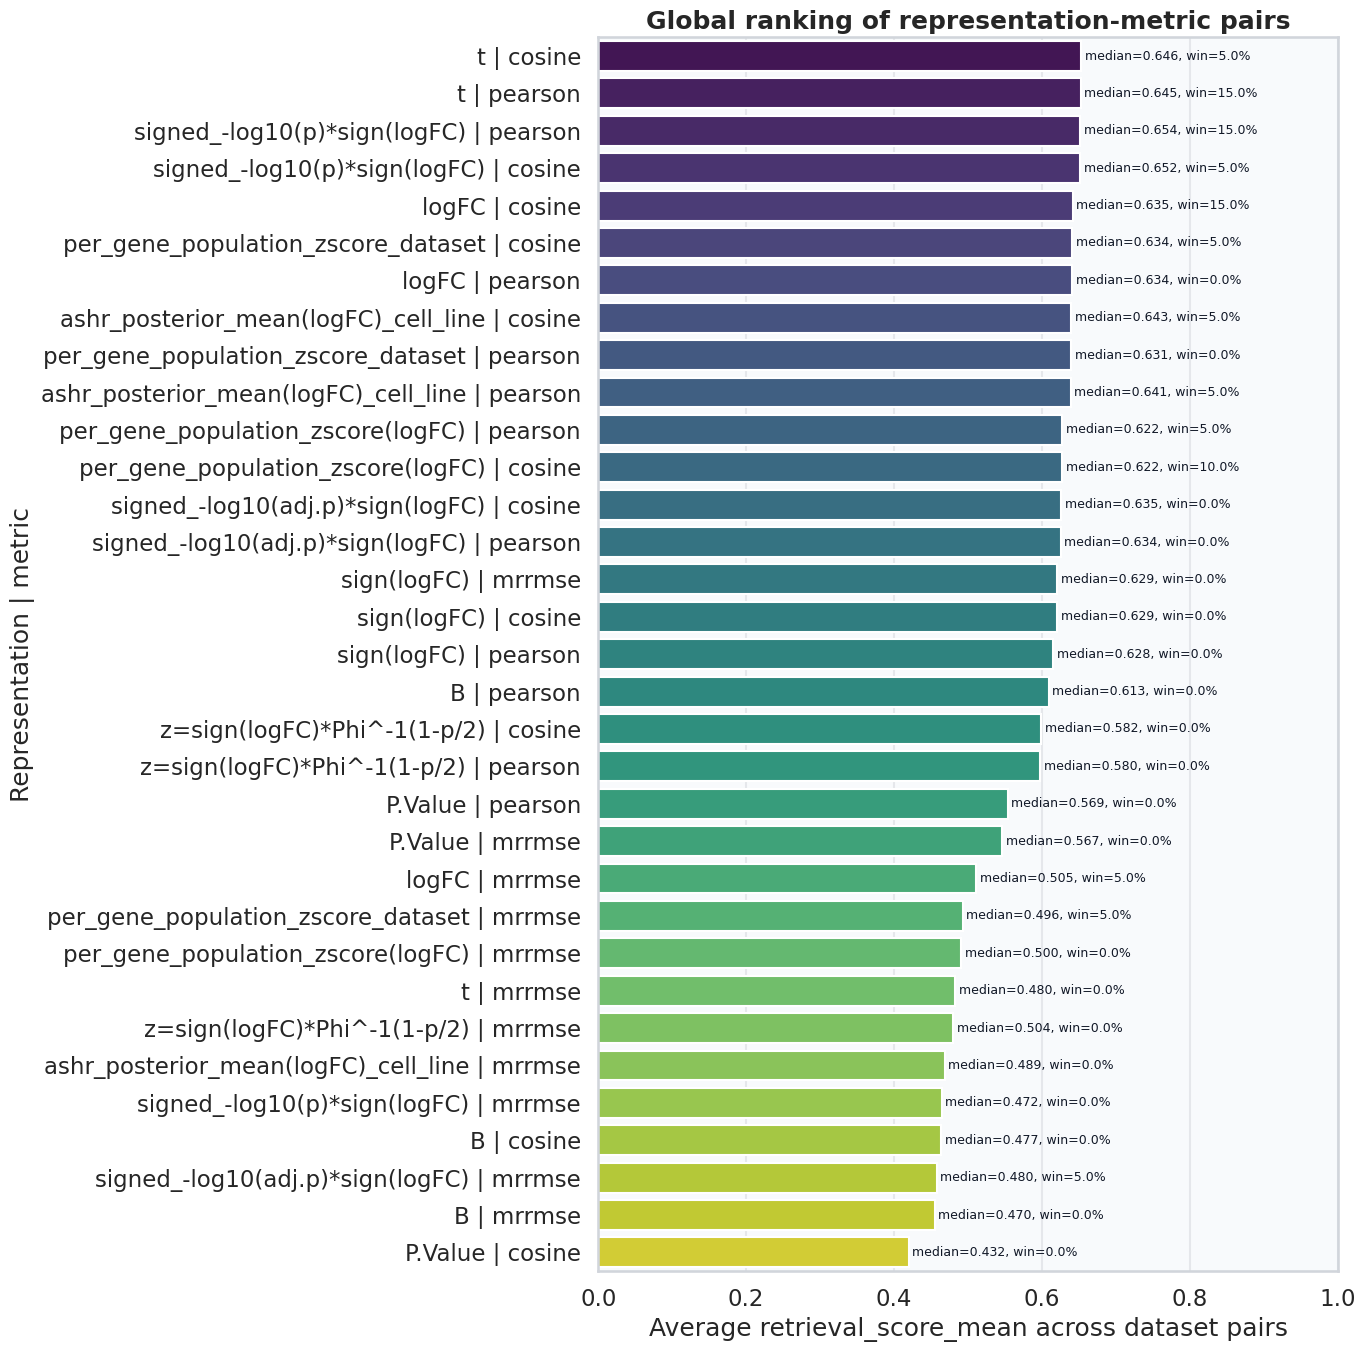

In [7]:
# Compare representation+metric pairs across dataset pairs.
summary_with_config = summary_overall_df.copy()
summary_with_config["config"] = (
    summary_with_config["representation"].astype(str)
    + " | "
    + summary_with_config["metric"].astype(str)
)

config_summary = (
    summary_with_config.groupby(["representation", "metric"], as_index=False)
    .agg(
        n_pairs=("pair", "nunique"),
        avg_retrieval_score_mean=("retrieval_score_mean", "mean"),
        median_retrieval_score_mean=("retrieval_score_mean", "median"),
        avg_retrieval_score_median=("retrieval_score_median", "mean"),
        median_retrieval_score_median=("retrieval_score_median", "median"),
    )
)

pair_winners = (
    summary_with_config.sort_values(
        ["retrieval_score_mean", "retrieval_score_median"],
        ascending=False,
    )
    .groupby(["query_dataset", "db_dataset"], as_index=False)
    .first()
)
winner_share = (
    pair_winners["config"].value_counts(normalize=True)
    .rename("pair_win_fraction")
    .rename_axis("config")
    .reset_index()
)
winner_count = (
    pair_winners["config"].value_counts()
    .rename("pair_win_count")
    .rename_axis("config")
    .reset_index()
)

config_summary["config"] = config_summary["representation"] + " | " + config_summary["metric"]
config_summary = (
    config_summary.merge(winner_count, on="config", how="left")
    .merge(winner_share, on="config", how="left")
    .fillna({"pair_win_count": 0, "pair_win_fraction": 0.0})
)
config_summary["pair_win_count"] = config_summary["pair_win_count"].astype(int)
config_summary = config_summary.sort_values(
    [
        "avg_retrieval_score_mean",
        "median_retrieval_score_mean",
        "avg_retrieval_score_median",
    ],
    ascending=False,
).reset_index(drop=True)

TOP_REPRESENTATION = config_summary.loc[0, "representation"]
TOP_METRIC = config_summary.loc[0, "metric"]
TOP_CONFIG = f"{TOP_REPRESENTATION} | {TOP_METRIC}"

n_pairs_total = pair_winners["pair"].nunique()
top_pair_win_count = int(config_summary.loc[0, "pair_win_count"])
top_pair_win_fraction = float(config_summary.loc[0, "pair_win_fraction"])

print(f"Top representation-metric by global average score: {TOP_CONFIG}")
print(
    f"It is the per-pair winner in {top_pair_win_count}/{n_pairs_total} dataset pairs "
    f"({top_pair_win_fraction:.1%})."
)

display(
    config_summary[
        [
            "representation",
            "metric",
            "n_pairs",
            "avg_retrieval_score_mean",
            "median_retrieval_score_mean",
            "avg_retrieval_score_median",
            "median_retrieval_score_median",
            "pair_win_count",
            "pair_win_fraction",
        ]
    ]
)

plt.figure(figsize=(14, max(5, 0.42 * len(config_summary))))
ax = sns.barplot(
    data=config_summary,
    y="config",
    x="avg_retrieval_score_mean",
    hue="config",
    dodge=False,
    legend=False,
    palette="viridis",
)
ax.set_xlim(0, 1)
ax.set_xlabel("Average retrieval_score_mean across dataset pairs")
ax.set_ylabel("Representation | metric")
ax.set_title("Global ranking of representation-metric pairs")

for i, (_, row) in enumerate(config_summary.iterrows()):
    ax.text(
        min(row["avg_retrieval_score_mean"] + 0.005, 0.995),
        i,
        f"median={row['median_retrieval_score_mean']:.3f}, win={row['pair_win_fraction']:.1%}",
        va="center",
        fontsize=9,
        color="#111827",
    )

plt.tight_layout()
plt.show()


In [8]:
config_summary[
        [
            "representation",
            "metric",
            "n_pairs",
            "avg_retrieval_score_mean",
            "median_retrieval_score_mean",
            "avg_retrieval_score_median",
            "median_retrieval_score_median",
            "pair_win_count",
            "pair_win_fraction",
        ]
    ].to_csv(output_dir / "visualize_retrieval_results_config_summary.csv", index=False)

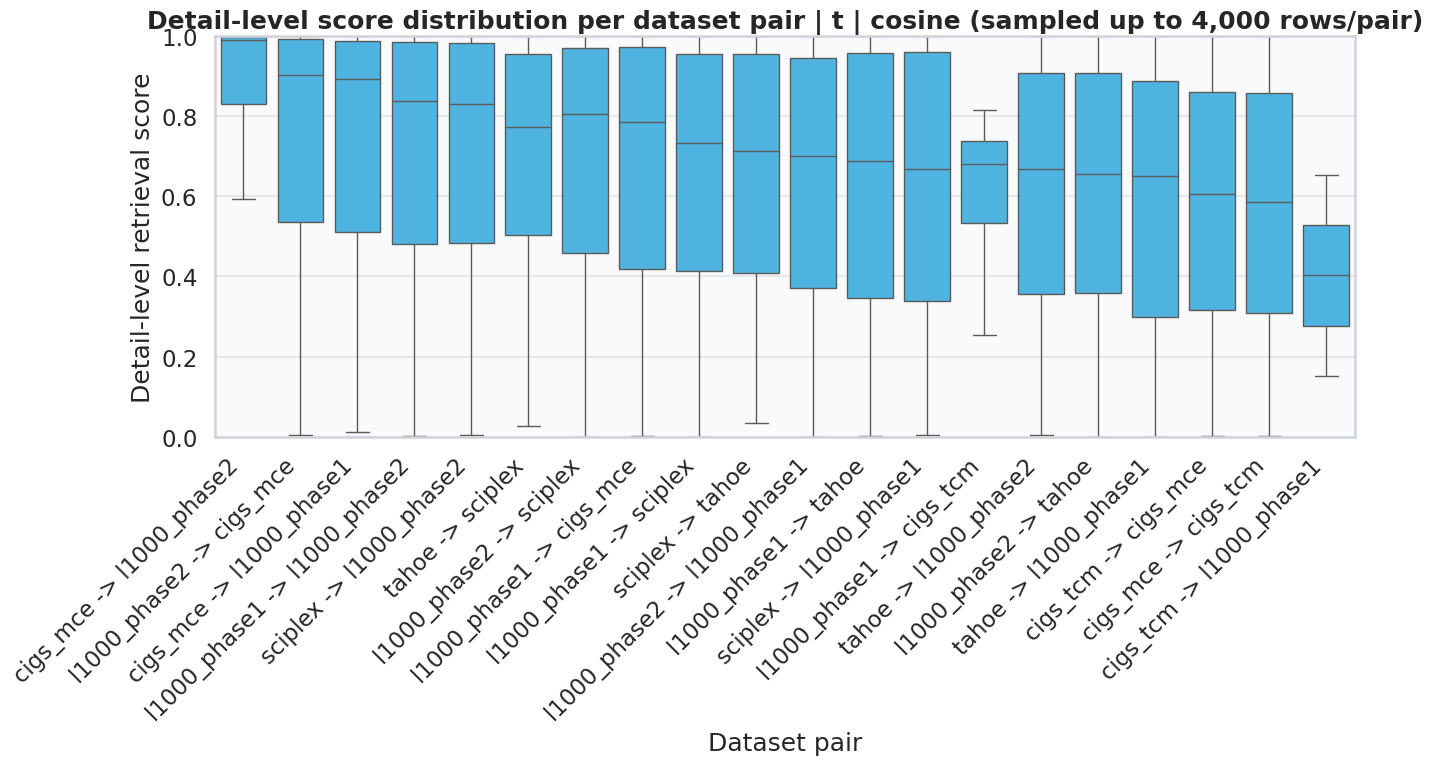

,query_dataset,db_dataset,pair,n_queries,retrieval_score_mean,retrieval_score_median
0,cigs_mce,l1000_phase2,cigs_mce -> l1000_phase2,72,0.864301,0.992059
1,l1000_phase2,cigs_mce,l1000_phase2 -> cigs_mce,1006,0.745224,0.904629
2,cigs_mce,l1000_phase1,cigs_mce -> l1000_phase1,133,0.731516,0.894628
3,l1000_phase1,l1000_phase2,l1000_phase1 -> l1000_phase2,16358,0.710785,0.839544
4,sciplex,l1000_phase2,sciplex -> l1000_phase2,561,0.708721,0.830696
5,tahoe,sciplex,tahoe -> sciplex,72,0.704987,0.773823
6,l1000_phase2,sciplex,l1000_phase2 -> sciplex,1032,0.696145,0.805142
7,l1000_phase1,cigs_mce,l1000_phase1 -> cigs_mce,1047,0.676767,0.785197
8,l1000_phase1,sciplex,l1000_phase1 -> sciplex,1005,0.660709,0.733844
9,sciplex,tahoe,sciplex -> tahoe,119,0.652126,0.713528


In [9]:
def sample_per_group(df: pd.DataFrame, group_cols: list[str], n_per_group: int, random_state: int = 0) -> pd.DataFrame:
    if n_per_group <= 0:
        return df
    frames = []
    for _, g in df.groupby(group_cols, dropna=False, sort=False):
        if len(g) > n_per_group:
            frames.append(g.sample(n=n_per_group, random_state=random_state))
        else:
            frames.append(g)
    return pd.concat(frames, ignore_index=True) if frames else df


top_detail_df = detail_df[
    (detail_df["representation"] == TOP_REPRESENTATION)
    & (detail_df["metric"] == TOP_METRIC)
].copy()

if top_detail_df.empty:
    raise ValueError(f"No detail rows found for top configuration: {TOP_CONFIG}")

pair_scores_top = summary_overall_df[
    (summary_overall_df["representation"] == TOP_REPRESENTATION)
    & (summary_overall_df["metric"] == TOP_METRIC)
].copy()
pair_scores_top["pair"] = pair_scores_top["query_dataset"] + " -> " + pair_scores_top["db_dataset"]
pair_order_top = pair_scores_top.sort_values("retrieval_score_mean", ascending=False)["pair"].tolist()

sampled_top_detail_df = sample_per_group(
    top_detail_df,
    group_cols=["pair"],
    n_per_group=DETAIL_SAMPLE_PER_GROUP,
    random_state=RANDOM_STATE,
)

plt.figure(figsize=(max(14, 0.7 * len(pair_order_top)), 8))
sns.boxplot(
    data=sampled_top_detail_df,
    x="pair",
    y="retrieval_score",
    order=pair_order_top,
    showfliers=False,
    color="#38BDF8",
    linewidth=1.0,
)
plt.ylim(0, 1)
plt.xlabel("Dataset pair")
plt.ylabel("Detail-level retrieval score")
plt.xticks(rotation=45, ha="right")
plt.title(
    f"Detail-level score distribution per dataset pair | {TOP_CONFIG} "
    f"(sampled up to {DETAIL_SAMPLE_PER_GROUP:,} rows/pair)"
)
plt.tight_layout()
plt.show()

top_detail_pair_stats = (
    top_detail_df.groupby(["query_dataset", "db_dataset", "pair"], as_index=False)
    .agg(
        n_queries=("retrieval_score", "size"),
        retrieval_score_mean=("retrieval_score", "mean"),
        retrieval_score_median=("retrieval_score", "median"),
    )
    .sort_values("retrieval_score_mean", ascending=False)
    .reset_index(drop=True)
)
display(top_detail_pair_stats)


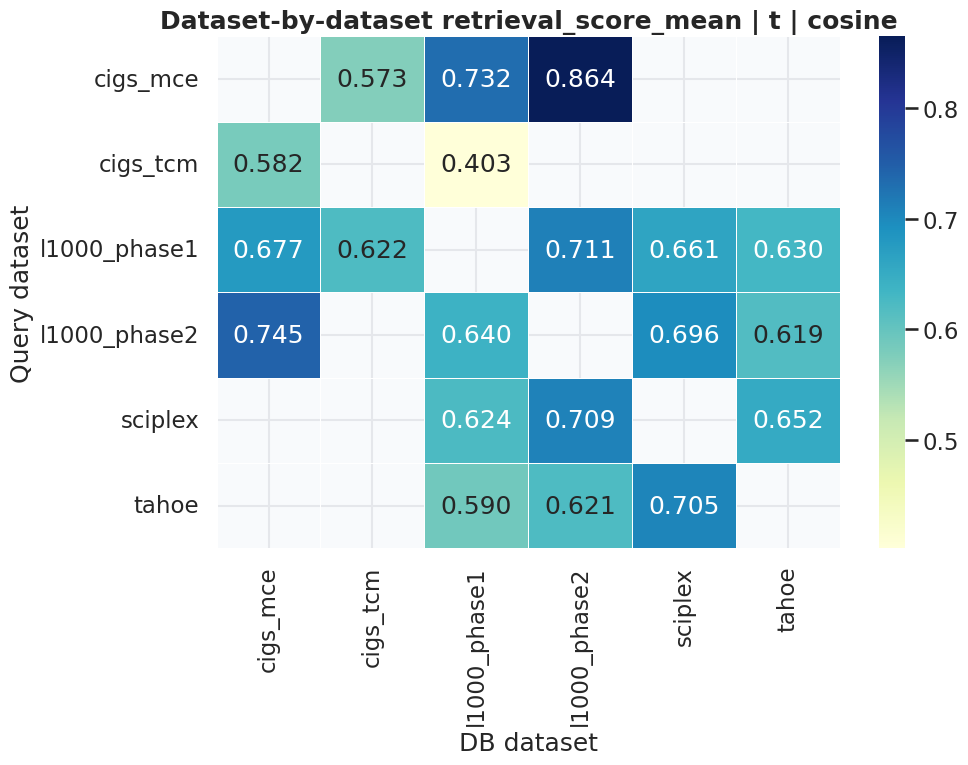

Mean retrieval score by DB dataset (column means):


,db_dataset,db_mean
0,cigs_mce,0.667912
1,cigs_tcm,0.597499
2,l1000_phase1,0.597651
3,l1000_phase2,0.726174
4,sciplex,0.687280
5,tahoe,0.633552


Mean retrieval score by Query dataset (row means):


,query_dataset,query_mean
0,cigs_mce,0.722886
1,cigs_tcm,0.492171
2,l1000_phase1,0.660064
3,l1000_phase2,0.675055
4,sciplex,0.661664
5,tahoe,0.638550


Per-dataset score (mean of query_mean and db_mean):


,dataset,query_mean,db_mean,dataset_score_mean_query_db
0,l1000_phase2,0.675055,0.726174,0.700615
1,cigs_mce,0.722886,0.667912,0.695399
2,sciplex,0.661664,0.687280,0.674472
3,tahoe,0.638550,0.633552,0.636051
4,l1000_phase1,0.660064,0.597651,0.628857
5,cigs_tcm,0.492171,0.597499,0.544835


,query_dataset,db_dataset,retrieval_score_mean,retrieval_score_median,n_queries
0,cigs_mce,cigs_tcm,0.572840,0.585015,2043
1,cigs_mce,l1000_phase1,0.731516,0.894628,133
2,cigs_mce,l1000_phase2,0.864301,0.992059,72
3,cigs_tcm,cigs_mce,0.581745,0.608229,4489
4,cigs_tcm,l1000_phase1,0.402597,0.402597,2
5,l1000_phase1,cigs_mce,0.676767,0.785197,1047
6,l1000_phase1,cigs_tcm,0.622158,0.680005,8
7,l1000_phase1,l1000_phase2,0.710785,0.839544,16358
8,l1000_phase1,sciplex,0.660709,0.733844,1005
9,l1000_phase1,tahoe,0.629899,0.688771,633


In [10]:
# Dataset-by-dataset heatmap for the top representation+metric.
top_summary_df = summary_overall_df[
    (summary_overall_df["representation"] == TOP_REPRESENTATION)
    & (summary_overall_df["metric"] == TOP_METRIC)
].copy()

if top_summary_df.empty:
    raise ValueError(f"No summary rows found for top configuration: {TOP_CONFIG}")

heatmap_df = (
    top_summary_df.pivot(index="query_dataset", columns="db_dataset", values="retrieval_score_mean")
    .sort_index(axis=0)
    .sort_index(axis=1)
)

fig_w = max(8, 1.4 * len(heatmap_df.columns) + 2)
fig_h = max(6, 1.0 * len(heatmap_df.index) + 2)

plt.figure(figsize=(fig_w, fig_h))
sns.heatmap(
    heatmap_df,
    cmap="YlGnBu",
    annot=True,
    fmt=".3f",
    linewidths=0.5,
    linecolor="white",
    vmin=float(top_summary_df["retrieval_score_mean"].min()),
    vmax=float(top_summary_df["retrieval_score_mean"].max()),
)
plt.xlabel("DB dataset")
plt.ylabel("Query dataset")
plt.title(f"Dataset-by-dataset retrieval_score_mean | {TOP_CONFIG}")
plt.tight_layout()
plt.show()


column_means = heatmap_df.mean(axis=0).rename("db_mean").sort_index()
row_means = heatmap_df.mean(axis=1).rename("query_mean").sort_index()

all_datasets = sorted(set(row_means.index).union(set(column_means.index)))
dataset_scores_df = pd.DataFrame({"dataset": all_datasets}).set_index("dataset")
dataset_scores_df["query_mean"] = row_means.reindex(all_datasets)
dataset_scores_df["db_mean"] = column_means.reindex(all_datasets)
dataset_scores_df["dataset_score_mean_query_db"] = dataset_scores_df[["query_mean", "db_mean"]].mean(axis=1)
dataset_scores_df = dataset_scores_df.reset_index()

print("Mean retrieval score by DB dataset (column means):")
display(column_means.reset_index().rename(columns={"index": "db_dataset"}))

print("Mean retrieval score by Query dataset (row means):")
display(row_means.reset_index().rename(columns={"index": "query_dataset"}))

print("Per-dataset score (mean of query_mean and db_mean):")
display(dataset_scores_df.sort_values("dataset_score_mean_query_db", ascending=False).reset_index(drop=True))

display(
    top_summary_df[
        [
            "query_dataset",
            "db_dataset",
            "retrieval_score_mean",
            "retrieval_score_median",
            "n_queries",
        ]
    ]
    .sort_values(["query_dataset", "db_dataset"])
    .reset_index(drop=True)
)


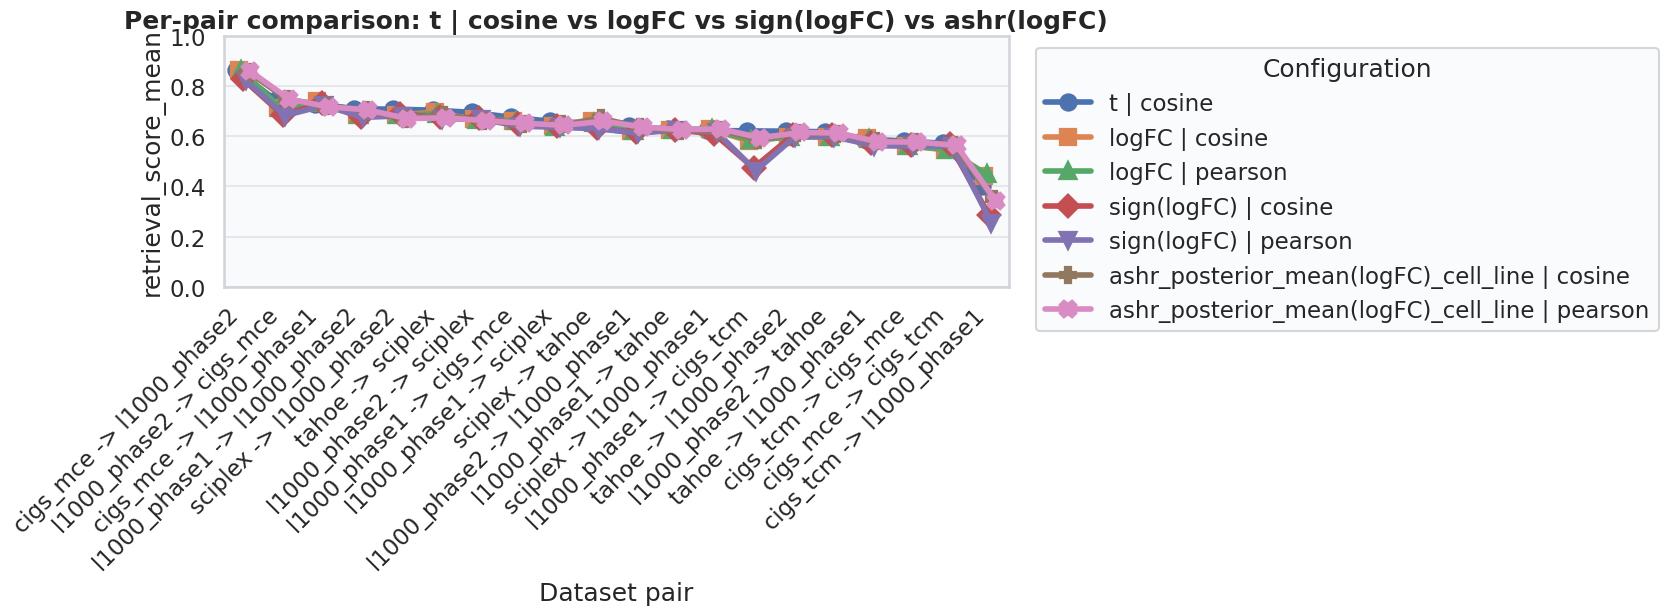

config,pair,t | cosine,logFC | cosine,logFC | pearson,sign(logFC) | cosine,sign(logFC) | pearson,ashr_posterior_mean(logFC)_cell_line | cosine,ashr_posterior_mean(logFC)_cell_line | pearson
0,cigs_mce -> l1000_phase2,0.864301,0.866066,0.865158,0.827802,0.825731,0.859075,0.860305
1,l1000_phase2 -> cigs_mce,0.745224,0.714053,0.713683,0.686282,0.683167,0.748146,0.748532
2,cigs_mce -> l1000_phase1,0.731516,0.741962,0.734672,0.731688,0.723877,0.722905,0.717976
3,l1000_phase1 -> l1000_phase2,0.710785,0.686783,0.686783,0.677448,0.676262,0.705493,0.705973
4,sciplex -> l1000_phase2,0.708721,0.685421,0.685011,0.689454,0.682329,0.671012,0.671441
5,tahoe -> sciplex,0.704987,0.696574,0.690474,0.675733,0.671185,0.684754,0.674288
6,l1000_phase2 -> sciplex,0.696145,0.667647,0.666936,0.674558,0.667752,0.663406,0.662653
7,l1000_phase1 -> cigs_mce,0.676767,0.661377,0.662928,0.651425,0.641235,0.651360,0.652581
8,l1000_phase1 -> sciplex,0.660709,0.641319,0.639414,0.640327,0.636285,0.648073,0.644113
9,sciplex -> tahoe,0.652126,0.660448,0.653731,0.632459,0.630653,0.671764,0.660745


In [11]:
# Compare the top configuration with logFC, sign(logFC), and ASHR.
comparison_df = summary_overall_df.copy()
comparison_df["config"] = comparison_df["representation"].astype(str) + " | " + comparison_df["metric"].astype(str)

available_reps = set(comparison_df["representation"].astype(str))
has_direction = "sign(logFC)" in available_reps
has_ashr = ASHR_REPRESENTATION in available_reps

comparison_configs = list(
    dict.fromkeys(
        [
            TOP_CONFIG,
            "logFC | cosine",
            "logFC | pearson",
            *(["sign(logFC) | cosine", "sign(logFC) | pearson"] if has_direction else []),
            *(
                [f"{ASHR_REPRESENTATION} | cosine", f"{ASHR_REPRESENTATION} | pearson"]
                if has_ashr
                else []
            ),
        ]
    )
)

comparison_mask = comparison_df["config"].isin(comparison_configs)
comparison_df = comparison_df.loc[comparison_mask].copy()
comparison_df["config"] = pd.Categorical(comparison_df["config"], categories=comparison_configs, ordered=True)
comparison_df = comparison_df.dropna(subset=["config"]).copy()

order_config = TOP_CONFIG if TOP_CONFIG in set(comparison_df["config"].astype(str)) else comparison_configs[0]
pair_order_compare = (
    comparison_df.loc[comparison_df["config"] == order_config]
    .sort_values("retrieval_score_mean", ascending=False)["pair"]
    .tolist()
)
remaining_pairs = [p for p in sorted(comparison_df["pair"].unique().tolist()) if p not in pair_order_compare]
pair_order_compare = pair_order_compare + remaining_pairs

marker_cycle = ["o", "s", "^", "D", "v", "P", "X"]
markers = [marker_cycle[i % len(marker_cycle)] for i in range(len(comparison_configs))]
plt.figure(figsize=(max(14, 0.85 * len(pair_order_compare)), 6.5))
sns.pointplot(
    data=comparison_df,
    x="pair",
    y="retrieval_score_mean",
    hue="config",
    order=pair_order_compare,
    errorbar=None,
    dodge=0.35,
    markers=markers,
    linestyles="-",
)
plt.ylim(0, 1)
plt.xlabel("Dataset pair")
plt.ylabel("retrieval_score_mean")
plt.xticks(rotation=45, ha="right")
title = f"Per-pair comparison: {TOP_CONFIG} vs logFC"
if has_direction:
    title += " vs sign(logFC)"
if has_ashr:
    title += " vs ashr(logFC)"
plt.title(title)
plt.legend(title="Configuration", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

comparison_pivot = (
    comparison_df.pivot_table(index="pair", columns="config", values="retrieval_score_mean", observed=False)
    .reindex(pair_order_compare)
    .reset_index()
)
display(comparison_pivot)


Task detail files found: 792/792 (100.0%)
  sign(logFC) detail files: 72/72


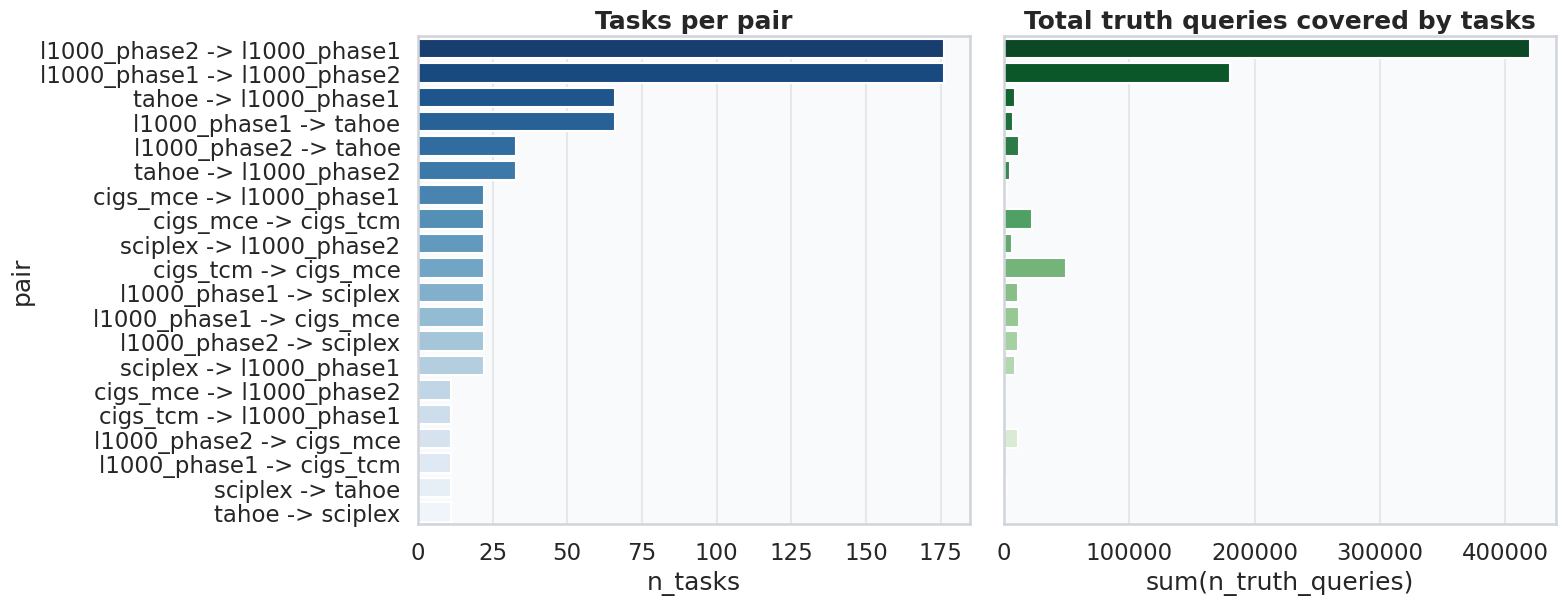

,pair,n_tasks,n_truth_queries
11,l1000_phase2 -> l1000_phase1,176,419452
7,l1000_phase1 -> l1000_phase2,176,179938
17,tahoe -> l1000_phase1,66,8514
9,l1000_phase1 -> tahoe,66,6963
13,l1000_phase2 -> tahoe,33,11803
18,tahoe -> l1000_phase2,33,4818
1,cigs_mce -> l1000_phase1,22,1463
0,cigs_mce -> cigs_tcm,22,22473
15,sciplex -> l1000_phase2,22,6171
3,cigs_tcm -> cigs_mce,22,49379


,pair,n_cell_types,n_truth_queries,mean_shared_cids
11,l1000_phase2 -> l1000_phase1,16,38132,316.000000
7,l1000_phase1 -> l1000_phase2,16,16358,316.000000
3,cigs_tcm -> cigs_mce,2,4489,955.000000
0,cigs_mce -> cigs_tcm,2,2043,955.000000
13,l1000_phase2 -> tahoe,3,1073,47.666667
5,l1000_phase1 -> cigs_mce,2,1047,63.500000
12,l1000_phase2 -> sciplex,2,1032,64.000000
10,l1000_phase2 -> cigs_mce,1,1006,68.000000
8,l1000_phase1 -> sciplex,2,1005,88.500000
14,sciplex -> l1000_phase1,2,781,88.500000


In [12]:
if tasks_df.empty and truth_summary_df.empty:
    print("No tasks/truth files found for this run. Skipping diagnostics.")
else:
    if not tasks_df.empty:
        # Check task files across source runs.
        task_dirs = [
            run_dir / "tasks"
            for run_dir in (results_dir, direction_dir, ashr_dir, zscore_dir)
            if run_dir is not None
        ]

        def detail_file_exists(name: object) -> bool:
            if pd.isna(name) or not str(name).strip():
                return False
            return any((task_dir / str(name)).exists() for task_dir in task_dirs)

        tasks_diag = tasks_df.copy()
        tasks_diag["detail_file_exists"] = tasks_diag["task_detail_file"].map(detail_file_exists)
        completion = tasks_diag["detail_file_exists"].mean()
        n_sign = int((tasks_diag["representation"].astype(str) == "sign(logFC)").sum())
        n_sign_found = int(
            (
                (tasks_diag["representation"].astype(str) == "sign(logFC)")
                & tasks_diag["detail_file_exists"]
            ).sum()
        )
        print(
            f"Task detail files found: {tasks_diag['detail_file_exists'].sum():,}/{len(tasks_diag):,} "
            f"({completion:.1%})"
        )
        if n_sign:
            print(f"  sign(logFC) detail files: {n_sign_found}/{n_sign}")

        tasks_per_pair = (
            tasks_diag.groupby("pair", as_index=False)
            .agg(
                n_tasks=("task_id", "count"),
                n_truth_queries=("n_truth_queries", "sum"),
            )
            .sort_values("n_tasks", ascending=False)
        )

        fig, axes = plt.subplots(1, 2, figsize=(16, max(5, 0.32 * len(tasks_per_pair))), sharey=True)
        sns.barplot(
            data=tasks_per_pair,
            y="pair",
            x="n_tasks",
            hue="pair",
            dodge=False,
            legend=False,
            ax=axes[0],
            palette="Blues_r",
        )
        axes[0].set_title("Tasks per pair")
        axes[0].set_xlabel("n_tasks")
        axes[0].set_ylabel("pair")

        sns.barplot(
            data=tasks_per_pair,
            y="pair",
            x="n_truth_queries",
            hue="pair",
            dodge=False,
            legend=False,
            ax=axes[1],
            palette="Greens_r",
        )
        axes[1].set_title("Total truth queries covered by tasks")
        axes[1].set_xlabel("sum(n_truth_queries)")
        axes[1].set_ylabel("")

        plt.tight_layout()
        plt.show()

        display(tasks_per_pair.head(20))

    if not truth_summary_df.empty:
        truth_by_pair = (
            truth_summary_df.groupby("pair", as_index=False)
            .agg(
                n_cell_types=("query_cell_type", "nunique"),
                n_truth_queries=("n_truth_queries", "sum"),
                mean_shared_cids=("n_shared_pubchem_cids", "mean"),
            )
            .sort_values("n_truth_queries", ascending=False)
        )
        display(truth_by_pair)
            
